<a href="https://colab.research.google.com/github/JUMRA-id/Regresi-Kota-Serang/blob/main/JUMRA%7COlahDataRegresiBergandaKotaSerang_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **REGRESI LINEAR BERGANDA – KOTA SERANG**

Saya mengambil Variabel Kota Serang Yaitu:

**Variabel Dependent (Y)** = PE (Pertumbuhan Ekonomi)

**Variabel Independent (X₁)** = DBH_Lainnya

**Variabel Independent (X₂)** = DAK_Nonfisik

In [ ]:
# IMPORT LIBRARY
import numpy as np
import pandas as pd
import statsmodels.api as sm
import plotly.graph_objects as go

######IMPORT DATA

In [ ]:

# MEMBACA DATA & MEMILIH KOTA SERANG
URL = "https://raw.githubusercontent.com/Alam-A99/DATAAKSI/main/dataset_fiskal_97_hipoFull.csv"
try:
    data_all = pd.read_csv(URL)
except Exception:
    data_all = pd.read_csv("dataset_fiskal_97_hipoFull.csv")

df = data_all[data_all["Kota"] == "Kota Serang"].reset_index(drop=True)

# Ambil hanya variabel yang dipakai
df = df[["Tahun", "DBH_Lainnya", "DAK_Nonfisik", "PE"]]
print(df)
print("\nJumlah observasi:", len(df))

    Tahun  DBH_Lainnya  DAK_Nonfisik    PE
0    2014        35.37        119.26  3.13
1    2015        45.52         89.96  4.82
2    2016        63.41         79.95  6.32
3    2017        45.22        104.04  5.18
4    2018        52.43        124.14  4.37
5    2019        42.32        139.29  3.93
6    2020        67.44         74.25  5.66
7    2021        89.23        136.03  7.63
8    2022        55.63        127.10  6.03
9    2023        50.04        158.49  2.45
10   2024        59.23        116.53  4.76

Jumlah observasi: 11


######OLAH DATA

In [ ]:
# VARIABEL INDEPENDEN & DEPENDEN

X = df[["DBH_Lainnya", "DAK_Nonfisik"]]
y = df["PE"]

X_model = sm.add_constant(X)

model = sm.OLS(y, X_model)
results = model.fit()

print("\n")
print("=" * 70)
print("HASIL REGRESI LINEAR BERGANDA – KOTA SERANG")
print("=" * 70)
print(results.summary())


# MENGAMBIL KOEFISIEN REGRESI
intercept = results.params["const"]
coef_dbh = results.params["DBH_Lainnya"]
coef_dak = results.params["DAK_Nonfisik"]

r_squared = results.rsquared
adjusted_r_squared = results.rsquared_adj


# MEMBUAT PERSAMAAN REGRESI
persamaan = (
    f"Ŷ = {intercept:.3f}"
    f" + ({coef_dbh:.3f}) X₁"
    f" + ({coef_dak:.3f}) X₂"
)

print("\n")
print("=" * 70)
print("                    PERSAMAAN REGRESI")
print("=" * 70)
print(persamaan)
print("X₁ = DBH_Lainnya, X₂ = DAK_Nonfisik, Y = PE (Pertumbuhan Ekonomi)")

print(f"\nR²            = {r_squared:.4f}")
print(f"Adjusted R²   = {adjusted_r_squared:.4f}")
print(f"F-statistic   = {results.fvalue:.3f} (p = {results.f_pvalue:.4f})")


# MENGHITUNG NILAI PREDIKSI
df["Prediksi"] = results.predict(X_model)
df["Residual"] = df["PE"] - df["Prediksi"]

print("\n")
print("=" * 70)
print("                  DATA AKTUAL & PREDIKSI")
print("=" * 70)
print(df[["Tahun", "DBH_Lainnya", "DAK_Nonfisik", "PE", "Prediksi", "Residual"]].round(2))


# MEMBUAT GRID UNTUK BIDANG REGRESI
x1 = np.linspace(df["DBH_Lainnya"].min(), df["DBH_Lainnya"].max(), 40)
x2 = np.linspace(df["DAK_Nonfisik"].min(), df["DAK_Nonfisik"].max(), 40)
X1, X2 = np.meshgrid(x1, x2)


# MENGHITUNG NILAI Y PADA BIDANG REGRESI
Y = intercept + coef_dbh * X1 + coef_dak * X2


# MEMBUAT FIGURE 3D
fig = go.Figure()


# MENAMPILKAN DATA AKTUAL
fig.add_trace(
    go.Scatter3d(
        x=df["DBH_Lainnya"],
        y=df["DAK_Nonfisik"],
        z=df["PE"],
        mode="markers",
        marker=dict(size=7, color="red", opacity=0.9),
        name="Data Aktual",
        text=[f"Tahun {t}" for t in df["Tahun"]],
        hovertemplate=(
            "<b>%{text}</b><br>"
            "DBH Lainnya: %{x}<br>"
            "DAK Nonfisik: %{y}<br>"
            "Pertumbuhan Ekonomi: %{z}"
            "<extra></extra>"
        ),
    )
)


# MENAMPILKAN BIDANG REGRESI
fig.add_trace(
    go.Surface(
        x=X1, y=X2, z=Y,
        opacity=0.60,
        colorscale="Viridis",
        name="Regression Plane",
        hovertemplate=(
            "DBH Lainnya: %{x:.2f}<br>"
            "DAK Nonfisik: %{y:.2f}<br>"
            "Prediksi PE: %{z:.2f}"
            "<extra></extra>"
        ),
    )
)

# MENGATUR TAMPILAN GRAFIK
fig.update_layout(
    title={
        "text": (
            "REGRESI LINEAR BERGANDA 3D – KOTA SERANG"
            "<br>"
            f"<sup>{persamaan} | "
            f"R² = {r_squared:.3f}</sup>"
        ),
        "x": 0.5,
    },
    scene={
        "xaxis": {"title": "DBH Lainnya (X₁)"},
        "yaxis": {"title": "DAK Nonfisik (X₂)"},
        "zaxis": {"title": "Pertumbuhan Ekonomi (Y)"},
    },
    width=1000,
    height=750,
    margin={"l": 0, "r": 0, "b": 0, "t": 100},
    legend={"x": 0.02, "y": 0.98},
)


# MENAMPILKAN GRAFIK
fig.show()
fig.write_html("regresi_3d_kota_serang.html")



HASIL REGRESI LINEAR BERGANDA – KOTA SERANG
                            OLS Regression Results                            
Dep. Variable:                     PE   R-squared:                       0.742
Model:                            OLS   Adj. R-squared:                  0.677
Method:                 Least Squares   F-statistic:                     11.49
Date:                Sat, 10 Oct 2026   Prob (F-statistic):            0.00445
Time:                        01:24:01   Log-Likelihood:                -11.918
No. Observations:                  11   AIC:                             29.84
Df Residuals:                       8   BIC:                             31.03
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                   coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------
co

######VISUALISASI DATA GRAFIK KOTA SERANG

In [ ]:
# MENGATUR TAMPILAN GRAFIK
fig.update_layout(
    title={
        "text": (
            "REGRESI LINEAR BERGANDA 3D – KOTA SERANG"
            "<br>"
            f"<sup>{persamaan} | "
            f"R² = {r_squared:.3f}</sup>"
        ),
        "x": 0.5,
    },
    scene={
        "xaxis": {"title": "DBH Lainnya (X₁)"},
        "yaxis": {"title": "DAK Nonfisik (X₂)"},
        "zaxis": {"title": "Pertumbuhan Ekonomi (Y)"},
    },
    width=1000,
    height=750,
    margin={"l": 0, "r": 0, "b": 0, "t": 100},
    legend={"x": 0.02, "y": 0.98},
)


# MENAMPILKAN GRAFIK
fig.show()
fig.write_html("regresi_3d_kota_serang.html")

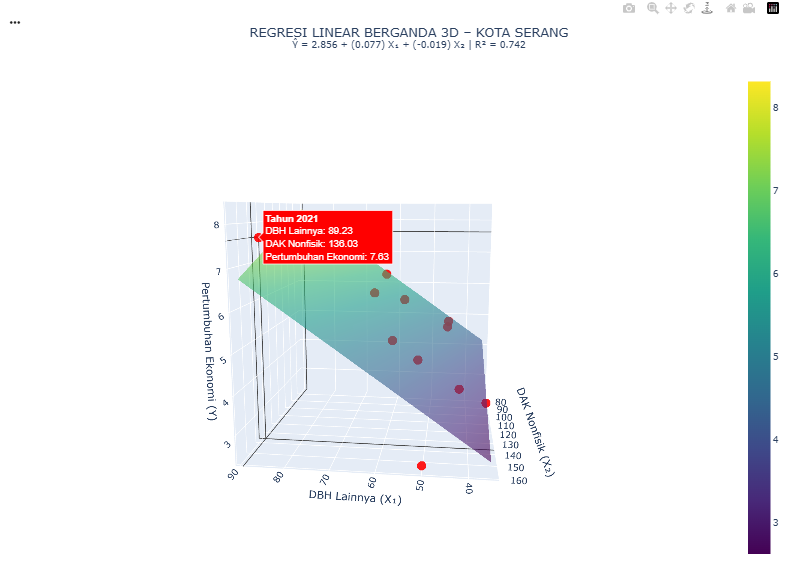

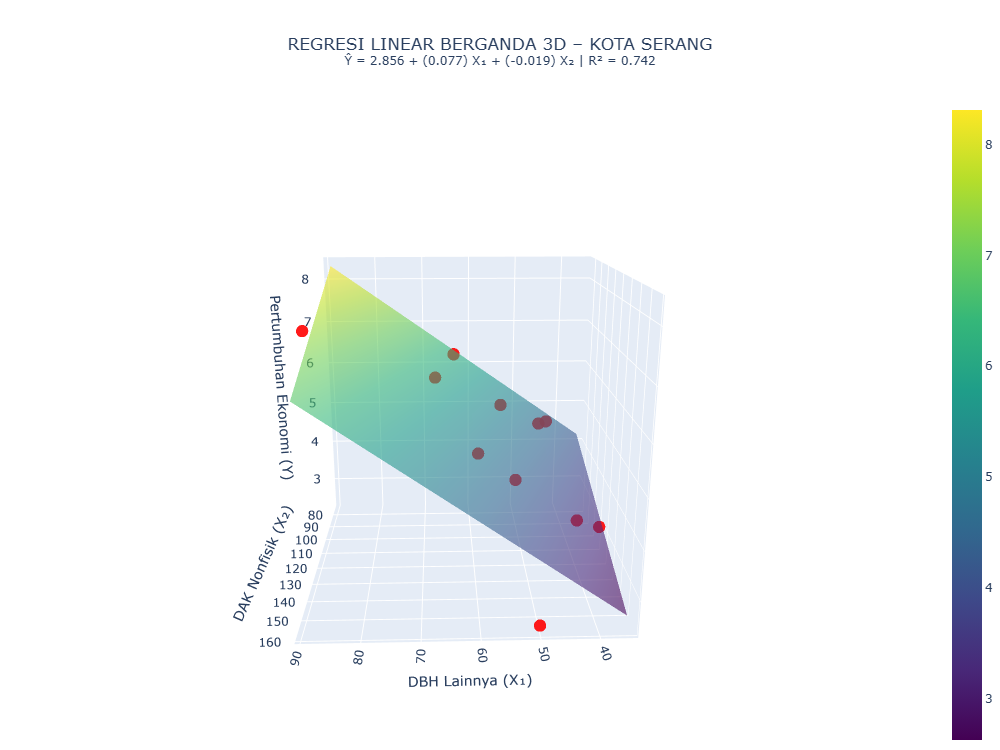


GRAFIK 3D REGRESI KOTA SERANG

https://colab.research.google.com/drive/1Bwg4Q6F9hdxFfgCb2I4zlMcFdCJyMBnV#scrollTo=4eTy9_u8TALS&fullscreenOutput=true
